In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df=pd.read_csv("india_job_market_2024-26.csv")
df=df.drop(columns=['Unnamed: 15','Unnamed: 16'])
df.head()

,Job_ID,Job_Title,Company,Company_Type,Industry,City,Experience_Level,Job_Type,Work_Mode,Salary_LPA,Skills_Required,Education_Required,Openings,Applicants,Date_Posted
0,IND2025000,Android Developer,Tech Mahindra,MNC,Information Technology,Remote,Senior (6-10 yrs),Full-Time,Remote,30.9,"Kotlin, Java, REST APIs",M.Tech/M.E.,3,276,31-10-2025
1,IND2025001,QA Engineer,Dream11,Indian Unicorn,Information Technology,Lucknow,Senior (6-10 yrs),Full-Time,Hybrid,58.6,"Selenium, Manual Testing, Postman, API Testing...",B.Tech/B.E.,3,325,19-05-2025
2,IND2025002,Business Analyst,HAL,PSU/Govt,EdTech,Remote,Senior (6-10 yrs),Full-Time,Remote,18.4,"JIRA, Excel, Power BI",MCA,5,559,21-08-2024
3,IND2025003,Cybersecurity Analyst,Groww,Startup,Information Technology,Mumbai,Mid (3-6 yrs),Full-Time,Hybrid,21.7,"Penetration Testing, Python, Ethical Hacking, ...",BCA,3,184,18-03-2026
4,IND2025004,Python Developer,Oracle,MNC,EdTech,Remote,Junior (1-3 yrs),Full-Time,Remote,8.0,"Docker, REST APIs, AWS, PostgreSQL",MCA,1,64,25-10-2024


In [7]:
top_jobs = df.groupby("Job_Title")["Openings"].sum()
top_jobs = top_jobs.sort_values(ascending=False).head(10)

top_jobs

Job_Title
Software Engineer       1253
Backend Developer       1041
Full Stack Developer     975
Data Analyst             931
Java Developer           911
Data Scientist           879
Python Developer         849
DevOps Engineer          760
Frontend Developer       753
React Developer          724
Name: Openings, dtype: int64

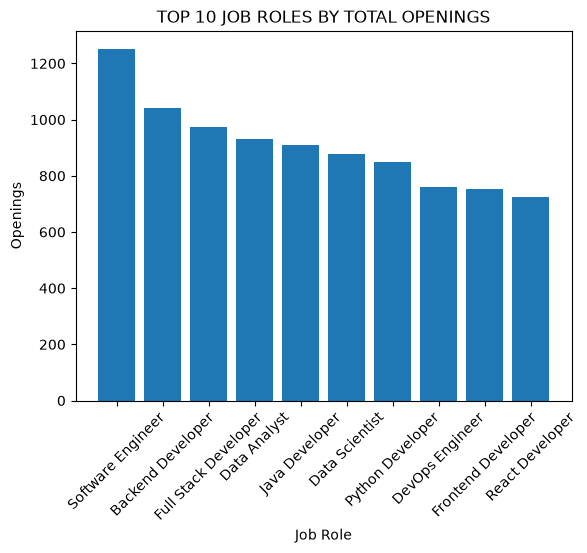

In [12]:
plt.bar(top_jobs.index,top_jobs.values)
plt.title('TOP 10 JOB ROLES BY TOTAL OPENINGS')
plt.xlabel('Job Role')
plt.ylabel('Openings')
plt.xticks(rotation=45)
plt.show()

In [19]:
salary_exp=df.groupby("Experience_Level")["Salary_LPA"].mean().round(2)
salary_exp

Experience_Level
Fresher (0-1 yr)      5.50
Junior (1-3 yrs)      9.92
Lead (10+ yrs)       52.95
Mid (3-6 yrs)        18.50
Senior (6-10 yrs)    34.19
Name: Salary_LPA, dtype: float64

In [20]:
salary_exp=salary_exp.reindex([
    "Fresher (0-1 yr)",
    "Junior (1-3 yrs)",
    "Mid (3-6 yrs)",
    "Senior (6-10 yrs)",
    "Lead (10+ yrs)"
])
salary_exp

Experience_Level
Fresher (0-1 yr)      5.50
Junior (1-3 yrs)      9.92
Mid (3-6 yrs)        18.50
Senior (6-10 yrs)    34.19
Lead (10+ yrs)       52.95
Name: Salary_LPA, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

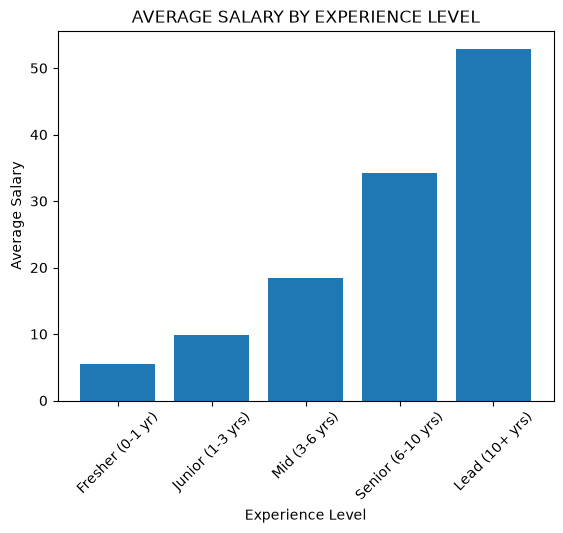

In [21]:
plt.bar(salary_exp.index,salary_exp.values)
plt.title("AVERAGE SALARY BY EXPERIENCE LEVEL")
plt.xlabel("Experience Level")
plt.ylabel("Average Salary")
plt.xticks(rotation=45)
plt.show

In [23]:
skills = []

for skill_list in df["Skills_Required"]:
    for skill in skill_list.split(","):
        skills.append(skill.strip())

skill_counts = pd.Series(skills).value_counts()

top_skills = skill_counts.head(10)
top_skills

Python        1579
REST APIs      998
AWS            867
SQL            847
Docker         836
Java           636
PostgreSQL     455
React          454
TypeScript     440
Agile          429
Name: count, dtype: int64

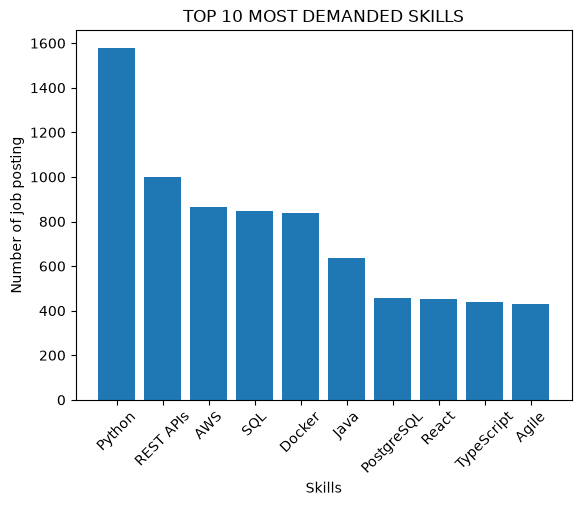

In [25]:
plt.bar(top_skills.index,top_skills.values)
plt.title("TOP 10 MOST DEMANDED SKILLS")
plt.xlabel("Skills")
plt.ylabel("Number of job posting")
plt.xticks(rotation=45)
plt.show()

In [26]:
fresher_jobs = df[df["Experience_Level"] == "Fresher (0-1 yr)"]

fresher_openings = fresher_jobs.groupby("Job_Title")["Openings"].sum()
fresher_openings = fresher_openings.sort_values(ascending=False).head(10)
fresher_openings

Job_Title
Java Developer               278
Software Engineer            256
Full Stack Developer         218
Data Analyst                 208
Backend Developer            203
DevOps Engineer              182
Python Developer             169
Data Engineer                167
Machine Learning Engineer    166
React Developer              159
Name: Openings, dtype: int64

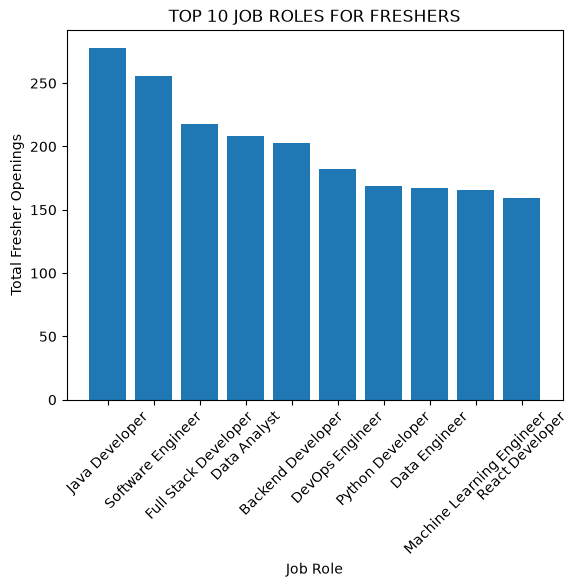

In [28]:
plt.bar(fresher_openings.index,fresher_openings.values)
plt.title("TOP 10 JOB ROLES FOR FRESHERS")
plt.xlabel("Job Role")
plt.ylabel("Total Fresher Openings")
plt.xticks(rotation=45)
plt.show()

In [33]:
fresher_competition=fresher_jobs.groupby("Job_Title")[["Applicants","Openings"]].sum()
fresher_competition["competition_ratio"]=(fresher_competition["Applicants"]/fresher_competition["Openings"])
fresher_competition


,Applicants,Openings,competition_ratio
Job_Title,,,
AI Engineer,10085,120,84.041667
Android Developer,11132,143,77.846154
Backend Developer,17293,203,85.187192
Blockchain Developer,2270,29,78.275862
Business Analyst,9361,131,71.458015
Cloud Engineer,12401,148,83.790541
Computer Vision Engineer,2679,37,72.405405
Cybersecurity Analyst,4474,58,77.137931
Data Analyst,18006,208,86.567308


In [36]:
lowest_competition=fresher_competition.sort_values("competition_ratio").head(10)
lowest_competition

,Applicants,Openings,competition_ratio
Job_Title,,,
Research Scientist,5552,88,63.090909
Business Analyst,9361,131,71.458015
Computer Vision Engineer,2679,37,72.405405
Software Engineer,18915,256,73.886719
Node.js Developer,10253,138,74.297101
UI/UX Designer,5802,78,74.384615
Cybersecurity Analyst,4474,58,77.137931
Android Developer,11132,143,77.846154
Blockchain Developer,2270,29,78.275862


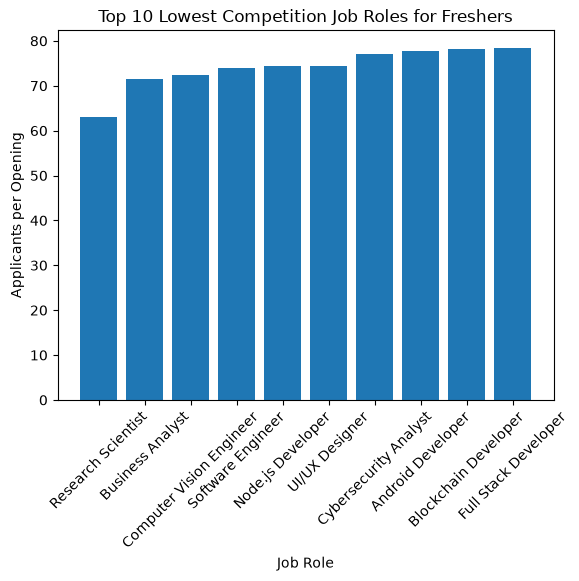

In [38]:

plt.bar(lowest_competition.index,lowest_competition["competition_ratio"])
plt.title("Top 10 Lowest Competition Job Roles for Freshers")
plt.xlabel("Job Role")
plt.ylabel("Applicants per Opening")
plt.xticks(rotation=45)
plt.show()

In [50]:
experience_openings=df.groupby("Experience_Level")["Openings"].sum()
experience_openings=experience_openings.reindex(["Fresher (0-1 yr)",
                            "Junior (1-3 yrs)",
                            "Mid (3-6 yrs)",
                            "Senior (6-10 yrs)",
                            "Lead (10+ yrs)"])
experience_openings

Experience_Level
Fresher (0-1 yr)     3980
Junior (1-3 yrs)     4504
Mid (3-6 yrs)        4894
Senior (6-10 yrs)    2967
Lead (10+ yrs)       1868
Name: Openings, dtype: int64

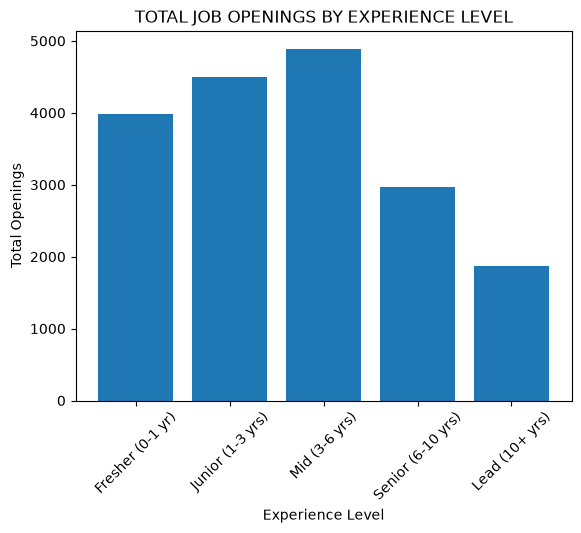

In [51]:
plt.bar(experience_openings.index,experience_openings.values)
plt.title("TOTAL JOB OPENINGS BY EXPERIENCE LEVEL")
plt.xlabel("Experience Level")
plt.ylabel("Total Openings")
plt.xticks(rotation=45)
plt.show()

In [52]:
work_mode=df["Work_Mode"].value_counts()
work_mode

Work_Mode
On-Site    2005
Hybrid     1728
Remote     1267
Name: count, dtype: int64

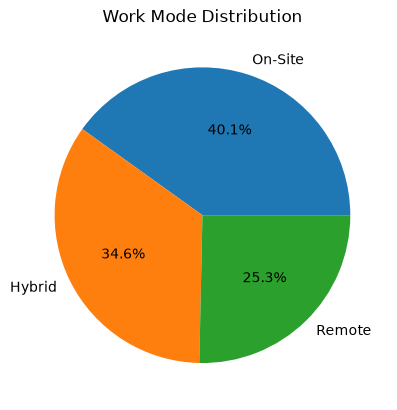

In [54]:
plt.pie(work_mode.values,labels=work_mode.index,autopct="%1.1f%%")
plt.title("Work Mode Distribution")
plt.show()

In [57]:
company_salary=df.groupby("Company_Type")["Salary_LPA"].mean().sort_values(ascending=False).round(2)
company_salary

Company_Type
Indian Unicorn    24.62
Startup           21.52
MNC               18.45
PSU/Govt          10.75
Name: Salary_LPA, dtype: float64

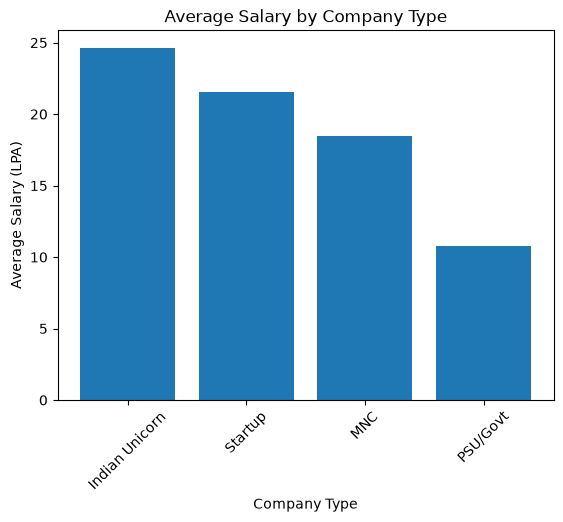

In [59]:
plt.bar(company_salary.index, company_salary.values)

plt.title("Average Salary by Company Type")
plt.xlabel("Company Type")
plt.ylabel("Average Salary (LPA)")

plt.xticks(rotation=45)
plt.show()


In [63]:
df['Date_Posted']=pd.to_datetime(df['Date_Posted'])
df['Month']=df['Date_Posted'].dt.to_period("M")
monthly_jobs=df["Month"].value_counts().sort_index()
monthly_jobs

Month
2024-06    215
2024-07    202
2024-08    222
2024-09    224
2024-10    239
2024-11    222
2024-12    198
2025-01    220
2025-02    192
2025-03    236
2025-04    216
2025-05    213
2025-06    219
2025-07    231
2025-08    211
2025-09    234
2025-10    233
2025-11    196
2025-12    228
2026-01    201
2026-02    207
2026-03    220
2026-04    221
Freq: M, Name: count, dtype: int64

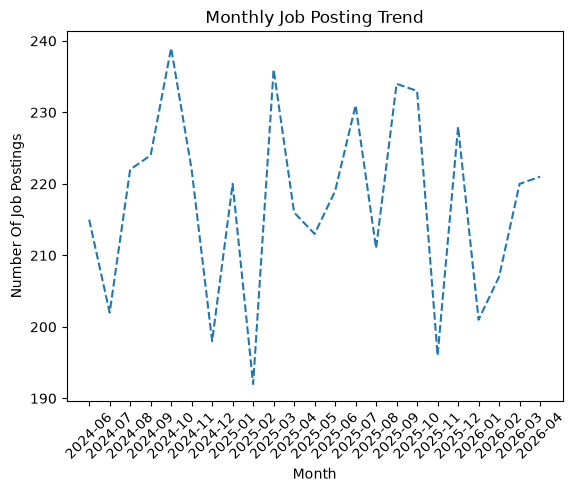

In [72]:
month=monthly_jobs.index.astype(str)
plt.plot(month,monthly_jobs.values,linestyle='dashed')
plt.title("Monthly Job Posting Trend")
plt.xlabel("Month")
plt.ylabel("Number Of Job Postings")
plt.xticks(rotation=45)
plt.show()

In [73]:
data_analyst_jobs=df[df['Job_Title']=="Data Analyst"]
data_analyst_skills=[]
for skill_list in data_analyst_jobs["Skills_Required"]:
    for skill in skill_list.split(","):
        data_analyst_skills.append(skill.strip())
data_analyst_skill_counts=pd.Series(data_analyst_skills).value_counts()
data_analyst_skill_counts

Data Visualization    178
Power BI              171
Statistics            169
SQL                   168
Tableau               160
Excel                 155
Python                143
Name: count, dtype: int64

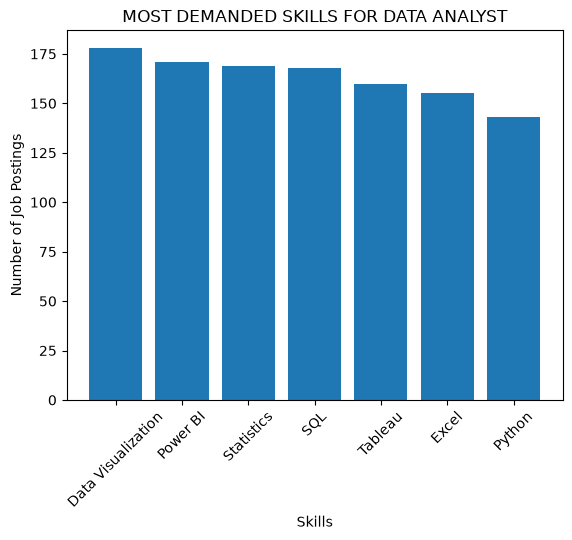

In [75]:
plt.bar(
    data_analyst_skill_counts.index,
    data_analyst_skill_counts.values
)

plt.title("MOST DEMANDED SKILLS FOR DATA ANALYST")
plt.xlabel("Skills")
plt.ylabel("Number of Job Postings")

plt.xticks(rotation=45)
plt.show()